# Mathematical Foundations for Large Language Models

**Purpose**: This notebook provides hands-on implementations of mathematical concepts underlying LLMs, including probability theory, optimization algorithms, backpropagation through transformers, scaling laws, and numerical stability considerations.

**Companion Theory**: This notebook works alongside the [Mathematical Foundations chapter](../index.md) which provides comprehensive theoretical background, derivations, and advanced mathematical concepts.

**Learning Path**: 
1. Read theory sections in the main chapter
2. Run corresponding notebook cells for hands-on practice  
3. Experiment with parameters to deepen understanding

**Dependencies**: PyTorch (CPU), NumPy, Matplotlib, Seaborn

**Reproducibility**: a fixed seed is set in the setup cell; run the cells in order for identical outputs. This notebook runs on CPU in well under a minute. Cells contain `assert` statements that fail loudly if a claimed result does not hold.

**Primary Sources**: 
- Kingma & Ba, 2014 - "Adam: A Method for Stochastic Optimization" ([arXiv:1412.6980](https://arxiv.org/abs/1412.6980))
- Kaplan et al., 2020 - "Scaling Laws for Neural Language Models" ([arXiv:2001.08361](https://arxiv.org/abs/2001.08361))
- Hoffmann et al., 2022 - "Training Compute-Optimal Large Language Models" ([arXiv:2203.15556](https://arxiv.org/abs/2203.15556))
- Ba et al., 2016 - "Layer Normalization" ([arXiv:1607.06450](https://arxiv.org/abs/1607.06450))

This notebook demonstrates the mathematical principles that enable effective training and scaling of large language models.

## 1. Setup and Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from typing import Optional, Tuple, List

# Set random seeds for reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

# Configure plotting
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

print("=" * 60)
print("Environment Setup Complete")
print("=" * 60)
print(f"PyTorch version: {torch.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Device: {'cuda' if torch.cuda.is_available() else 'cpu'}")
print(f"Random seed: {SEED}")
print("=" * 60)

Environment Setup Complete
PyTorch version: 2.14.1+cpu
NumPy version: 2.5.4
Device: cpu
Random seed: 42


(nb-math-information-theory)=
## 2. Probability and Information Theory

$$H(X) = -\sum_x P(x)\log_2 P(x), \qquad H(P,Q) = -\sum_x P(x)\log_2 Q(x), \qquad D_{KL}(P\,\|\,Q) = \sum_x P(x)\log_2\frac{P(x)}{Q(x)} = H(P,Q) - H(P)$$

Understanding probability distributions and information theory is fundamental to language modeling. This section explores entropy, cross-entropy, KL divergence, and their applications in LLMs.

**Theory Reference**: See Chapter 2, Section 1 for complete mathematical derivations and theoretical foundations.

In [2]:
def entropy(probs: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """
    Compute Shannon entropy of probability distribution, in bits.
    
    H(X) = -∑ P(x) log₂ P(x)
    
    Args:
        probs: Probability distribution [batch_size, num_classes]
        eps: Small constant for numerical stability
    
    Returns:
        Entropy values [batch_size]
    """
    return -torch.sum(probs * torch.log2(probs + eps), dim=-1)


def cross_entropy_loss(logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    """
    Compute cross-entropy loss between predictions and targets.
    
    H(P, Q) = -∑ P(x) log Q(x)
    
    Args:
        logits: Model outputs [batch_size, vocab_size]
        targets: True token indices [batch_size]
    
    Returns:
        Cross-entropy loss (scalar)
    """
    log_probs = F.log_softmax(logits, dim=-1)
    return F.nll_loss(log_probs, targets)


def kl_divergence(p: torch.Tensor, q: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """
    Compute Kullback-Leibler divergence between distributions.
    
    D_KL(P || Q) = ∑ P(x) log₂(P(x) / Q(x)), in bits. Where Q(x) = 0 and P(x) > 0 the
    true divergence is infinite; the eps clamp keeps it finite, so treat such values as 'very large'.
    
    Args:
        p: True distribution [batch_size, num_classes]
        q: Approximate distribution [batch_size, num_classes]
        eps: Small constant for numerical stability
    
    Returns:
        KL divergence values [batch_size]
    """
    return torch.sum(p * torch.log2((p + eps) / (q + eps)), dim=-1)


def perplexity(loss: torch.Tensor) -> torch.Tensor:
    """
    Convert cross-entropy loss to perplexity.
    
    Perplexity = exp(H(P, Q))
    
    Args:
        loss: Cross-entropy loss
    
    Returns:
        Perplexity value
    """
    return torch.exp(loss)


# Demonstration: Compare different distributions
print("Probability and Information Theory Demonstration")
print("=" * 60)

# Create sample distributions
vocab_size = 10
batch_size = 3

# Uniform distribution (high entropy)
uniform_dist = torch.ones(batch_size, vocab_size) / vocab_size

# Peaked distribution (low entropy)
peaked_dist = torch.zeros(batch_size, vocab_size)
peaked_dist[:, 0] = 0.9
peaked_dist[:, 1:] = 0.1 / (vocab_size - 1)

# Slightly uncertain distribution (medium entropy)
uncertain_dist = torch.zeros(batch_size, vocab_size)
uncertain_dist[:, 0] = 0.5
uncertain_dist[:, 1] = 0.3
uncertain_dist[:, 2:] = 0.2 / (vocab_size - 2)

# Compute entropies
uniform_entropy = entropy(uniform_dist)
peaked_entropy = entropy(peaked_dist)
uncertain_entropy = entropy(uncertain_dist)

print("\nEntropy Analysis:")
print(f"Uniform distribution entropy: {uniform_entropy[0]:.4f} bits")
print(f"Peaked distribution entropy: {peaked_entropy[0]:.4f} bits")
print(f"Uncertain distribution entropy: {uncertain_entropy[0]:.4f} bits")
print(f"Maximum possible entropy (log2 {vocab_size}): {math.log2(vocab_size):.4f} bits")
assert abs(uniform_entropy[0].item() - math.log2(vocab_size)) < 1e-4, "uniform entropy must equal log2(V) bits"

# Compute KL divergences
kl_uniform_peaked = kl_divergence(uniform_dist, peaked_dist)
kl_peaked_uniform = kl_divergence(peaked_dist, uniform_dist)

print("\nKL Divergence (asymmetric):")
print(f"D_KL(uniform || peaked): {kl_uniform_peaked[0]:.4f} bits")
print(f"D_KL(peaked || uniform): {kl_peaked_uniform[0]:.4f} bits")
print("Note: KL divergence is not symmetric!")

# Simulate an UNTRAINED language model: random logits. Its cross-entropy is in nats
# (F.nll_loss uses the natural log) and its perplexity is near the vocabulary size,
# which is what 'no better than guessing' looks like.
logits = torch.randn(batch_size, vocab_size)
targets = torch.randint(0, vocab_size, (batch_size,))
ce_loss = cross_entropy_loss(logits, targets)
ppl = perplexity(ce_loss)

print("\nLanguage Model Metrics:")
print(f"Cross-entropy loss (nats): {ce_loss:.4f}")
print(f"Perplexity of an untrained model (uniform would give {vocab_size}): {ppl:.4f}")
print("=" * 60)

Probability and Information Theory Demonstration

Entropy Analysis:
Uniform distribution entropy: 3.3219 bits
Peaked distribution entropy: 0.7860 bits
Uncertain distribution entropy: 2.0855 bits
Maximum possible entropy (log2 10): 3.3219 bits

KL Divergence (asymmetric):
D_KL(uniform || peaked): 2.5359 bits
D_KL(peaked || uniform): 2.5359 bits
Note: KL divergence is not symmetric!

Language Model Metrics:
Cross-entropy loss (nats): 4.1052
Perplexity of an untrained model (uniform would give 10): 60.6552


### Visualization: Entropy vs Distribution Shape

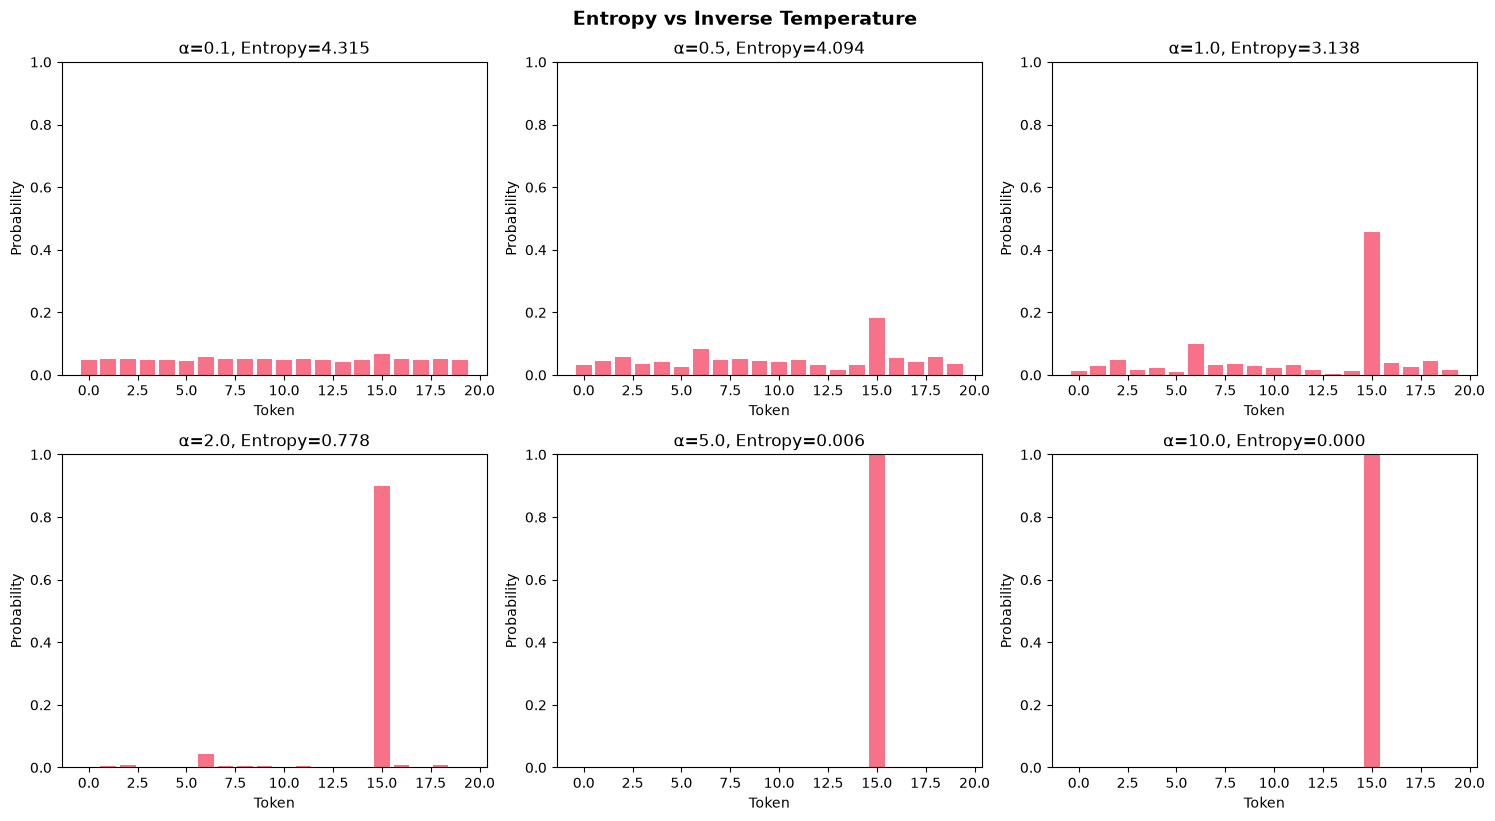

Observation: as alpha grows the softmax becomes more peaked and entropy falls.
Lower entropy means more predictable/certain predictions.


In [3]:
# Create distributions with varying sharpness: alpha scales the logits (an inverse temperature),
# so larger alpha gives a more peaked softmax on average.
alphas = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
vocab_size = 20

base_logits = torch.randn(vocab_size)  # same logits for every panel so only alpha changes
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for idx, alpha in enumerate(alphas):
    # Scale fixed random logits by alpha (inverse temperature)
    probs = torch.softmax(base_logits * alpha, dim=-1)
    ent = entropy(probs.unsqueeze(0))[0].item()
    
    # Plot
    axes[idx].bar(range(vocab_size), probs.numpy())
    axes[idx].set_title(f'α={alpha}, Entropy={ent:.3f}')
    axes[idx].set_xlabel('Token')
    axes[idx].set_ylabel('Probability')
    axes[idx].set_ylim(0, 1)

plt.tight_layout()
plt.suptitle('Entropy vs Inverse Temperature', y=1.02, fontsize=14, fontweight='bold')
plt.show()

print("Observation: as alpha grows the softmax becomes more peaked and entropy falls.")
print("Lower entropy means more predictable/certain predictions.")

(nb-math-optimizers)=
## 3. Optimization Algorithms

$$\text{SGD: } \theta_{t+1} = \theta_t - \eta g_t \qquad \text{Momentum: } v_{t+1} = \beta v_t + g_t,\; \theta_{t+1} = \theta_t - \eta v_{t+1}$$

$$\text{Adam: } m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t,\; v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2,\; \theta_{t+1} = \theta_t - \eta\,\frac{m_t/(1-\beta_1^t)}{\sqrt{v_t/(1-\beta_2^t)} + \epsilon}$$

This section implements and compares fundamental optimization algorithms used in LLM training: SGD, Momentum, and Adam.

**Theory Reference**: See Chapter 2, Section 2 for mathematical derivations and convergence analysis.

In [4]:
class SGDOptimizer:
    """Stochastic Gradient Descent with optional momentum."""
    
    def __init__(self, params: List[torch.Tensor], lr: float = 0.01, momentum: float = 0.0):
        """
        Initialize SGD optimizer.
        
        Args:
            params: Model parameters to optimize
            lr: Learning rate
            momentum: Momentum coefficient (0 for vanilla SGD)
        """
        self.params = list(params)
        self.lr = lr
        self.momentum = momentum
        self.velocities = [torch.zeros_like(p) for p in self.params]
        
    def step(self):
        """Perform single optimization step."""
        with torch.no_grad():
            for i, param in enumerate(self.params):
                if param.grad is None:
                    continue
                
                # Update velocity: v = β*v + ∇L
                self.velocities[i] = self.momentum * self.velocities[i] + param.grad
                
                # Update parameter: θ = θ - η*v
                param -= self.lr * self.velocities[i]
    
    def zero_grad(self):
        """Zero out gradients."""
        for param in self.params:
            if param.grad is not None:
                param.grad.zero_()


class AdamOptimizer:
    """Adam optimizer with bias correction."""
    
    def __init__(
        self,
        params: List[torch.Tensor],
        lr: float = 0.001,
        betas: Tuple[float, float] = (0.9, 0.999),
        eps: float = 1e-8,
        weight_decay: float = 0.0
    ):
        """
        Initialize Adam optimizer.
        
        Args:
            params: Model parameters to optimize
            lr: Learning rate
            betas: Coefficients for computing running averages (β₁, β₂)
            eps: Term added for numerical stability
            weight_decay: L2 penalty coefficient
        """
        self.params = list(params)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.weight_decay = weight_decay
        
        # Initialize moment estimates
        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]
        self.step_count = 0
    
    def step(self):
        """Perform single optimization step."""
        self.step_count += 1
        
        with torch.no_grad():
            for i, param in enumerate(self.params):
                if param.grad is None:
                    continue
                
                grad = param.grad
                
                # Add weight decay (L2 regularization)
                if self.weight_decay > 0:
                    grad = grad + self.weight_decay * param
                
                # Update biased first moment estimate: m = β₁*m + (1-β₁)*g
                self.m[i] = self.beta1 * self.m[i] + (1 - self.beta1) * grad
                
                # Update biased second moment estimate: v = β₂*v + (1-β₂)*g²
                self.v[i] = self.beta2 * self.v[i] + (1 - self.beta2) * grad.pow(2)
                
                # Compute bias-corrected moment estimates
                m_hat = self.m[i] / (1 - self.beta1 ** self.step_count)
                v_hat = self.v[i] / (1 - self.beta2 ** self.step_count)
                
                # Update parameters: θ = θ - η * m̂ / (√v̂ + ε)
                param -= self.lr * m_hat / (torch.sqrt(v_hat) + self.eps)
    
    def zero_grad(self):
        """Zero out gradients."""
        for param in self.params:
            if param.grad is not None:
                param.grad.zero_()


print("Optimizer implementations ready: SGD, SGD+Momentum, Adam")
print("Next: Compare optimization trajectories on a toy problem")

Optimizer implementations ready: SGD, SGD+Momentum, Adam
Next: Compare optimization trajectories on a toy problem


In [5]:
# Check the hand-written Adam against torch.optim.Adam for 10 steps on the same problem
torch.manual_seed(0)
p_ours = torch.randn(5, requires_grad=True)
p_ref = p_ours.detach().clone().requires_grad_(True)
ours = AdamOptimizer([p_ours], lr=0.1)
ref = torch.optim.Adam([p_ref], lr=0.1)
for _ in range(10):
    for p, opt in ((p_ours, ours), (p_ref, ref)):
        opt.zero_grad()
        (p ** 2).sum().backward()
        opt.step()
assert torch.allclose(p_ours, p_ref, atol=1e-6), "hand-written Adam must match torch.optim.Adam"
print("Hand-written Adam matches torch.optim.Adam after 10 steps:", torch.allclose(p_ours, p_ref, atol=1e-6))


Hand-written Adam matches torch.optim.Adam after 10 steps: True


(nb-math-rosenbrock)=
### Optimization Comparison: Rosenbrock Function

We'll compare different optimizers on the Rosenbrock function, a classic optimization benchmark with a narrow valley making it challenging for gradient descent.

What the run below shows (10,000 steps from (-1, -1)): Adam at lr 0.01 reaches (1, 1) to machine precision. Plain SGD at lr 0.001 creeps along the valley and ends near (0.99, 0.99). SGD with momentum 0.9 at the same lr diverges to NaN: momentum raises the effective step to η/(1-β) = 0.01, which is unstable in the steep direction of the valley (lowering its lr to 1e-4 makes it converge).

In [6]:
def rosenbrock(x: torch.Tensor, y: torch.Tensor, a: float = 1.0, b: float = 100.0) -> torch.Tensor:
    """
    Rosenbrock function: f(x,y) = (a-x)² + b(y-x²)²
    Global minimum at (a, a²) with f(a, a²) = 0
    """
    return (a - x)**2 + b * (y - x**2)**2


def optimize_rosenbrock(optimizer_class, optimizer_kwargs, num_steps=10000):
    """Run optimization and track trajectory."""
    # Initialize parameters far from optimum
    x = torch.tensor([-1.0], requires_grad=True)
    y = torch.tensor([-1.0], requires_grad=True)
    
    optimizer = optimizer_class([x, y], **optimizer_kwargs)
    
    trajectory_x = []
    trajectory_y = []
    losses = []
    
    for step in range(num_steps):
        optimizer.zero_grad()
        
        # Compute loss
        loss = rosenbrock(x, y)
        loss.backward()
        
        # Record trajectory
        trajectory_x.append(x.item())
        trajectory_y.append(y.item())
        losses.append(loss.item())
        
        # Update parameters
        optimizer.step()
    
    return np.array(trajectory_x), np.array(trajectory_y), np.array(losses)


# Compare different optimizers
optimizers_config = [
    ("SGD", SGDOptimizer, {"lr": 0.001, "momentum": 0.0}),
    ("SGD+Momentum", SGDOptimizer, {"lr": 0.001, "momentum": 0.9}),
    ("Adam", AdamOptimizer, {"lr": 0.01}),
]

results = {}
for name, opt_class, opt_kwargs in optimizers_config:
    print(f"Running {name}...")
    traj_x, traj_y, losses = optimize_rosenbrock(opt_class, opt_kwargs)
    results[name] = (traj_x, traj_y, losses)

print("Optimization runs complete!")

final = {name: (r[0][-1], r[1][-1], r[2][-1]) for name, r in results.items()}
for name, (fx, fy, fl) in final.items():
    print(f"{name:>13}: x={fx:.4f}, y={fy:.4f}, loss={fl:.3e}")
assert abs(final["Adam"][0] - 1) < 0.05 and abs(final["Adam"][1] - 1) < 0.05, "Adam should reach (1, 1) within 0.05"

Running SGD...


Running SGD+Momentum...


Running Adam...


Optimization runs complete!
          SGD: x=0.9943, y=0.9887, loss=3.221e-05
 SGD+Momentum: x=nan, y=nan, loss=nan
         Adam: x=1.0000, y=1.0000, loss=6.963e-13


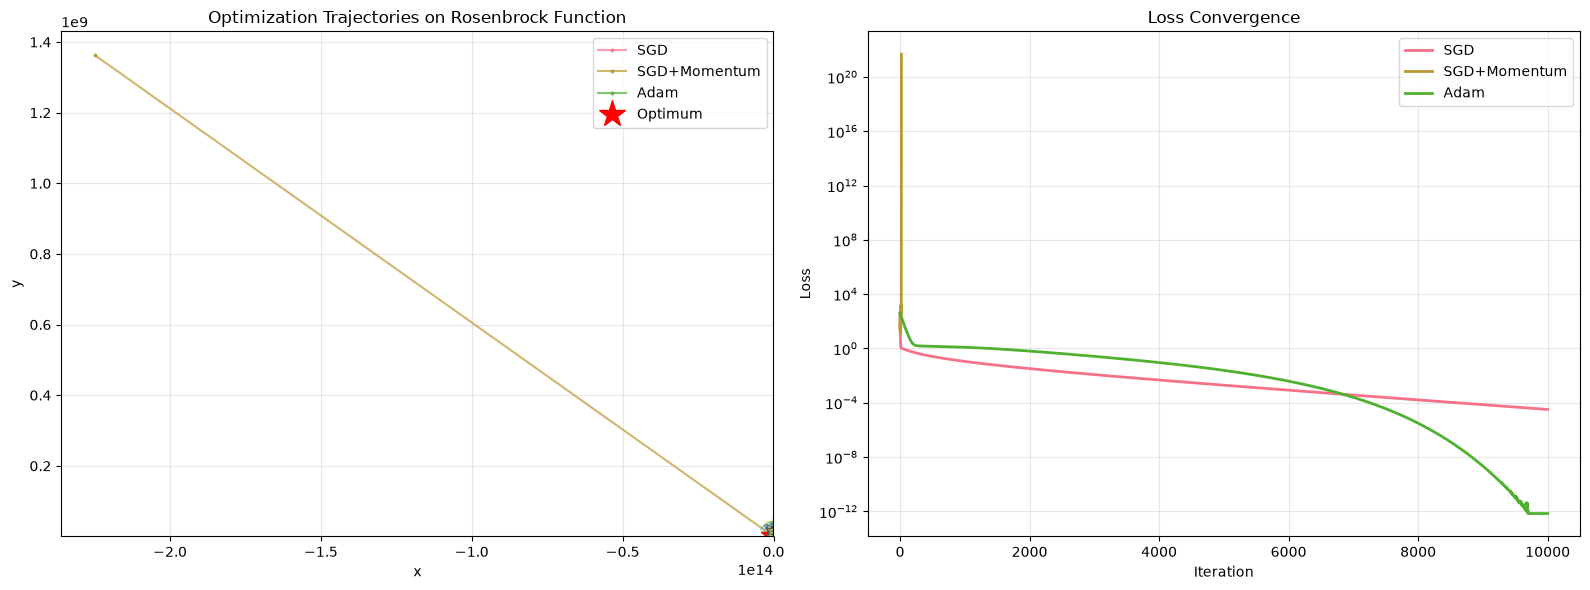


Final losses:
SGD: 0.000032
SGD+Momentum: nan
Adam: 0.000000


In [7]:
# Visualize optimization trajectories
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Create contour plot of Rosenbrock function
x_range = np.linspace(-2, 2, 100)
y_range = np.linspace(-1, 3, 100)
X, Y = np.meshgrid(x_range, y_range)
Z = (1 - X)**2 + 100 * (Y - X**2)**2

# Plot 1: Trajectories on contour
ax1 = axes[0]
contour = ax1.contour(X, Y, Z, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.6)
ax1.clabel(contour, inline=True, fontsize=8)

for name, (traj_x, traj_y, _) in results.items():
    ax1.plot(traj_x, traj_y, 'o-', label=name, markersize=2, linewidth=1.5, alpha=0.7)

ax1.plot(1, 1, 'r*', markersize=20, label='Optimum')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title('Optimization Trajectories on Rosenbrock Function')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Loss curves
ax2 = axes[1]
for name, (_, _, losses) in results.items():
    ax2.plot(losses, label=name, linewidth=2)

ax2.set_xlabel('Iteration')
ax2.set_ylabel('Loss')
ax2.set_title('Loss Convergence')
ax2.set_yscale('log')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nFinal losses:")
for name, (_, _, losses) in results.items():
    print(f"{name}: {losses[-1]:.6f}")

(nb-math-schedules)=
## 4. Learning Rate Scheduling

$$\eta_t = \begin{cases}\eta_{\max}\,\frac{t+1}{T_{\text{warmup}}} & t < T_{\text{warmup}} \\ \eta_{\min} + \tfrac12(\eta_{\max}-\eta_{\min})\left(1 + \cos\frac{\pi\,(t - T_{\text{warmup}})}{T_{\max} - T_{\text{warmup}}}\right) & \text{otherwise}\end{cases}$$

Learning rate schedules are critical for stable training. This section implements common schedules used in LLM training.

**Theory Reference**: See Chapter 2, Section 2.2 for mathematical analysis of different schedules.

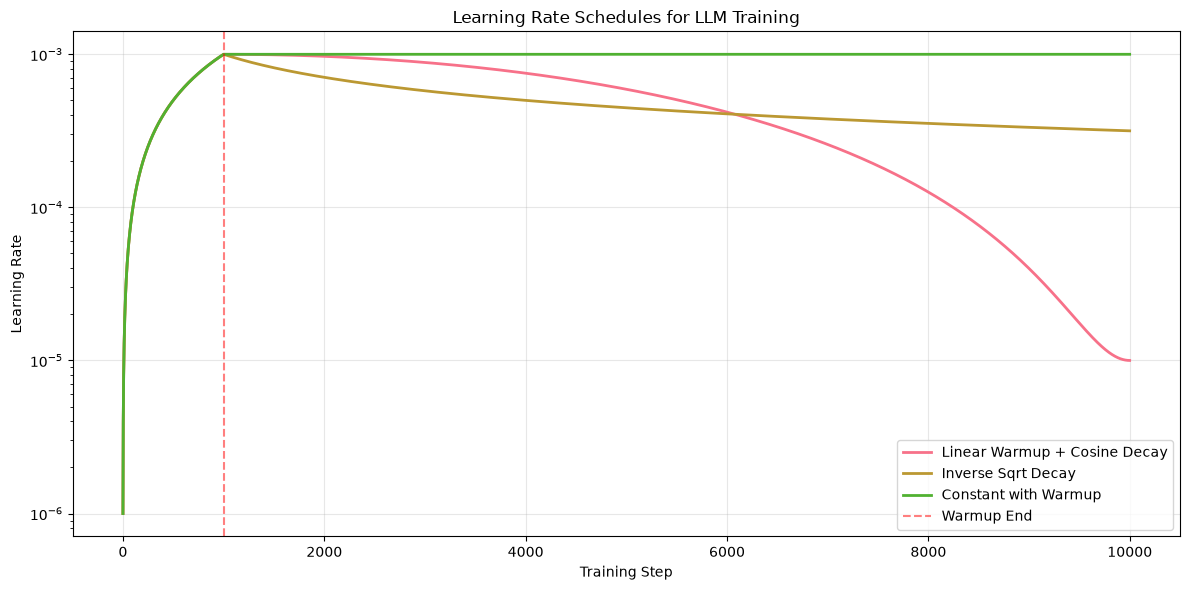

Warmup steps: 1000
Total steps: 10000
Max learning rate: 0.001
Min learning rate: 1e-05


In [8]:
class LearningRateScheduler:
    """Collection of learning rate schedules for LLM training."""
    
    @staticmethod
    def linear_warmup_cosine_decay(
        step: int,
        warmup_steps: int,
        max_steps: int,
        max_lr: float,
        min_lr: float
    ) -> float:
        """
        Linear warmup followed by cosine decay.
        
        Used by GPT-3, LLaMA and most LLMs since 2020 (BERT used linear decay).
        Step 0 is counted as the first warmup step, so the learning rate is never exactly 0.
        
        Args:
            step: Current training step
            warmup_steps: Number of warmup steps
            max_steps: Total training steps
            max_lr: Maximum learning rate
            min_lr: Minimum learning rate
        
        Returns:
            Learning rate for current step
        """
        if step < warmup_steps:
            # Linear warmup: lr = max_lr * ((step + 1) / warmup_steps)
            return max_lr * ((step + 1) / warmup_steps)
        else:
            # Cosine decay
            progress = min((step - warmup_steps) / (max_steps - warmup_steps), 1.0)  # hold at min_lr
            return min_lr + 0.5 * (max_lr - min_lr) * (1 + math.cos(math.pi * progress))
    
    @staticmethod
    def inverse_sqrt_decay(
        step: int,
        warmup_steps: int,
        max_lr: float
    ) -> float:
        """
        Inverse square root decay after warmup.
        
        Used in original Transformer paper.
        
        Args:
            step: Current training step
            warmup_steps: Number of warmup steps
            max_lr: Maximum learning rate
        
        Returns:
            Learning rate for current step
        """
        if step < warmup_steps:
            return max_lr * ((step + 1) / warmup_steps)
        else:
            return max_lr * math.sqrt(warmup_steps / step)
    
    @staticmethod
    def constant_with_warmup(
        step: int,
        warmup_steps: int,
        lr: float
    ) -> float:
        """
        Linear warmup to constant learning rate.
        
        Args:
            step: Current training step
            warmup_steps: Number of warmup steps
            lr: Target learning rate
        
        Returns:
            Learning rate for current step
        """
        if step < warmup_steps:
            return lr * ((step + 1) / warmup_steps)
        else:
            return lr


# Visualize different schedules
max_steps = 10000
warmup_steps = 1000
max_lr = 1e-3
min_lr = 1e-5

steps = np.arange(0, max_steps)
schedules = {
    'Linear Warmup + Cosine Decay': [
        LearningRateScheduler.linear_warmup_cosine_decay(
            s, warmup_steps, max_steps, max_lr, min_lr
        ) for s in steps
    ],
    'Inverse Sqrt Decay': [
        LearningRateScheduler.inverse_sqrt_decay(s, warmup_steps, max_lr) 
        for s in steps
    ],
    'Constant with Warmup': [
        LearningRateScheduler.constant_with_warmup(s, warmup_steps, max_lr)
        for s in steps
    ],
}

plt.figure(figsize=(12, 6))
for name, lrs in schedules.items():
    plt.plot(steps, lrs, label=name, linewidth=2)

plt.axvline(x=warmup_steps, color='red', linestyle='--', alpha=0.5, label='Warmup End')
plt.xlabel('Training Step')
plt.ylabel('Learning Rate')
plt.title('Learning Rate Schedules for LLM Training')
plt.legend()
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.tight_layout()
plt.show()

S = LearningRateScheduler
assert S.linear_warmup_cosine_decay(0, warmup_steps, max_steps, max_lr, min_lr) > 0
assert math.isclose(S.linear_warmup_cosine_decay(max_steps, warmup_steps, max_steps, max_lr, min_lr), min_lr)
assert math.isclose(S.linear_warmup_cosine_decay(max_steps + 500, warmup_steps, max_steps, max_lr, min_lr), min_lr)
print(f"Warmup steps: {warmup_steps}")
print(f"Total steps: {max_steps}")
print(f"Max learning rate: {max_lr}")
print(f"Min learning rate: {min_lr}")

(nb-math-backprop)=
## 5. Backpropagation Through Transformers

$$O = PV,\quad P = \mathrm{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right),\qquad \frac{\partial\mathcal{L}}{\partial S} = P \odot\left(G - (G\odot P)\mathbf{1}\mathbf{1}^T\right),\; G = \frac{\partial\mathcal{L}}{\partial O}V^T$$

Understanding gradient flow through transformer components is essential for effective training. This section implements and analyzes attention mechanisms and layer normalization.

**Theory Reference**: See Chapter 2, Section 3 for complete mathematical derivations.

Gradient Flow Analysis Through Attention
Query gradient norm: 14.1911
Key gradient norm: 13.8292
Value gradient norm: 34.2305

Attention weights shape: torch.Size([2, 1, 8, 8])
Output shape: torch.Size([2, 1, 8, 64])


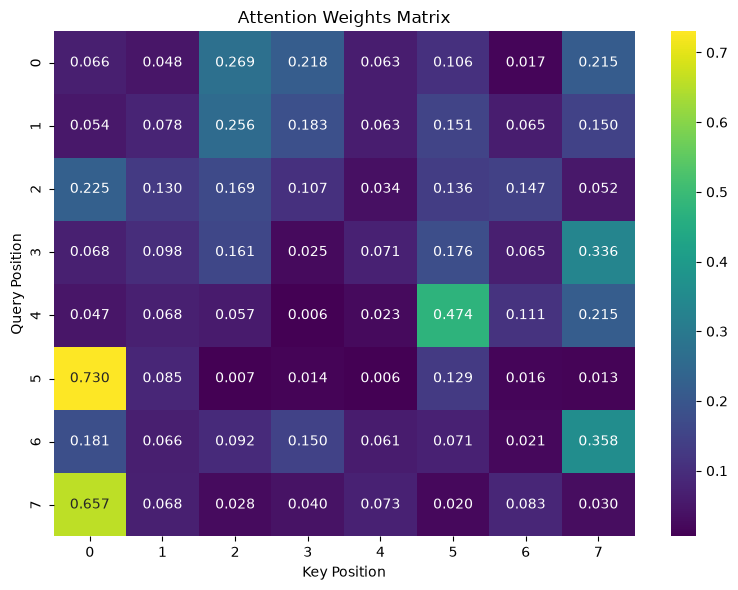

In [9]:
class ScaledDotProductAttention(nn.Module):
    """
    Scaled dot-product attention mechanism.
    
    Attention(Q, K, V) = softmax(QK^T / √d_k)V
    """
    
    def __init__(self, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
    
    def forward(
        self,
        query: torch.Tensor,
        key: torch.Tensor,
        value: torch.Tensor,
        mask: Optional[torch.Tensor] = None
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Compute scaled dot-product attention.
        
        Args:
            query: Query tensor [batch, heads, seq_len, d_k]
            key: Key tensor [batch, heads, seq_len, d_k]
            value: Value tensor [batch, heads, seq_len, d_v]
            mask: Optional attention mask
        
        Returns:
            output: Attention output [batch, heads, seq_len, d_v]
            attention_weights: Attention weights [batch, heads, seq_len, seq_len]
        """
        d_k = query.size(-1)
        
        # Compute attention scores: QK^T / √d_k
        scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(d_k)
        
        # Apply mask if provided
        if mask is not None:
            scores = scores.masked_fill(mask == 0, torch.finfo(scores.dtype).min)
        
        # Apply softmax to get attention weights
        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)
        
        # Apply attention weights to values
        output = torch.matmul(attention_weights, value)
        
        return output, attention_weights


def analyze_attention_gradients(
    batch_size: int = 2,
    seq_len: int = 8,
    d_model: int = 64
):
    """
    Analyze gradient flow through attention mechanism.
    """
    # Create attention module
    attention = ScaledDotProductAttention(dropout=0.0).eval()
    
    # Generate random Q, K, V with gradients enabled
    query = torch.randn(batch_size, 1, seq_len, d_model, requires_grad=True)
    key = torch.randn(batch_size, 1, seq_len, d_model, requires_grad=True)
    value = torch.randn(batch_size, 1, seq_len, d_model, requires_grad=True)
    
    # Forward pass
    output, attn_weights = attention(query, key, value)
    
    # Compute dummy loss (sum of outputs)
    loss = output.sum()
    loss.backward()
    
    # Analyze gradient magnitudes
    print("Gradient Flow Analysis Through Attention")
    print("=" * 60)
    print(f"Query gradient norm: {query.grad.norm().item():.4f}")
    print(f"Key gradient norm: {key.grad.norm().item():.4f}")
    print(f"Value gradient norm: {value.grad.norm().item():.4f}")
    assert torch.allclose(attn_weights.sum(-1), torch.ones_like(attn_weights.sum(-1)), atol=1e-5), "rows must sum to 1"
    print(f"\nAttention weights shape: {attn_weights.shape}")
    print(f"Output shape: {output.shape}")
    print("=" * 60)
    
    return attn_weights[0, 0].detach().numpy()

# Run analysis
attn_matrix = analyze_attention_gradients()

# Visualize attention weights
plt.figure(figsize=(8, 6))
sns.heatmap(attn_matrix, cmap='viridis', annot=True, fmt='.3f', cbar=True)
plt.xlabel('Key Position')
plt.ylabel('Query Position')
plt.title('Attention Weights Matrix')
plt.tight_layout()
plt.show()

(nb-math-layernorm)=
### Layer Normalization and Gradient Flow

$$y = \gamma \odot \frac{x-\mu}{\sqrt{\sigma^2+\epsilon}} + \beta, \qquad h_{l+1} = h_l + F(h_l) \;\Rightarrow\; \frac{\partial h_{l+1}}{\partial h_l} = I + \frac{\partial F}{\partial h_l}$$


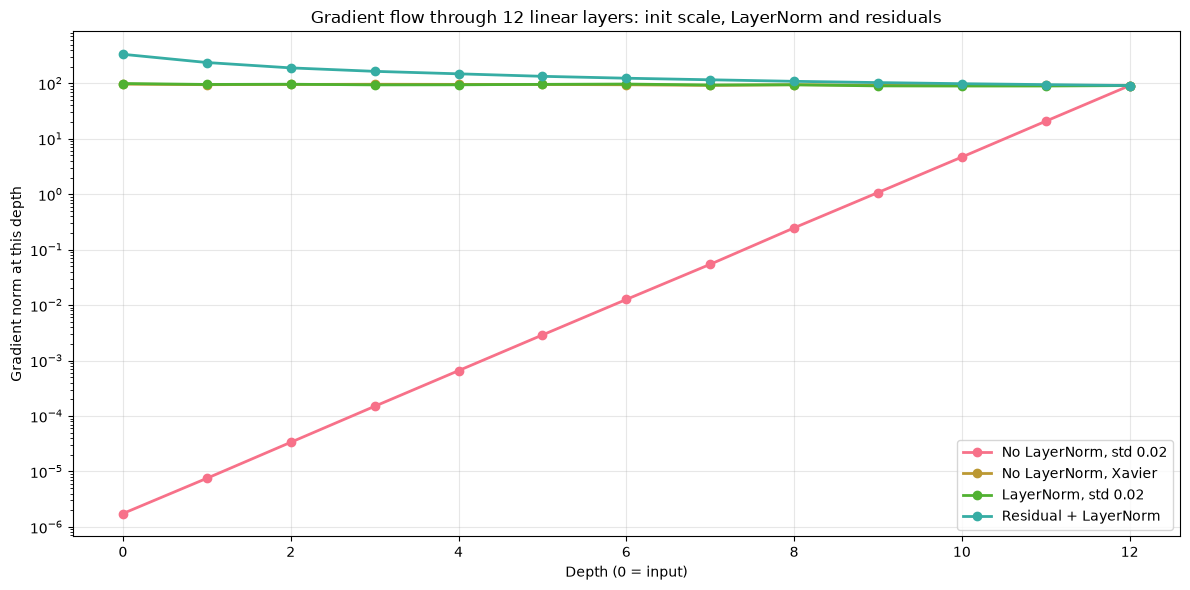

Gradient norm at the input (layer 0) vs at the last layer
No LayerNorm, std 0.02     layer0=1.742e-06  last=9.110e+01  ratio=1.912e-08
No LayerNorm, Xavier       layer0=9.669e+01  last=9.110e+01  ratio=1.061e+00
LayerNorm, std 0.02        layer0=9.926e+01  last=9.110e+01  ratio=1.090e+00
Residual + LayerNorm       layer0=3.338e+02  last=9.110e+01  ratio=3.664e+00
Takeaway: with weights of std 0.02 the gain per layer is 0.02*sqrt(128) ≈ 0.23, so the gradient
shrinks by ~0.23^12 ≈ 2e-8 by the input. LayerNorm fixes this, but so does a properly scaled
(Xavier) initialisation: the vanishing here is caused by the weight scale, not by the absence
of LayerNorm alone. Residual connections keep the gradient near 1 regardless.


In [10]:
class LayerNorm(nn.Module):
    """
    Layer normalization (Ba et al., 2016), forward pass only; autograd supplies gradients.

    y = γ ⊙ (x - μ) / σ + β,   σ = sqrt(var + ε)

    where μ and the biased variance are computed over the feature dimension.
    """

    def __init__(self, normalized_shape: int, eps: float = 1e-5):
        super().__init__()
        self.eps = eps
        self.gamma = nn.Parameter(torch.ones(normalized_shape))
        self.beta = nn.Parameter(torch.zeros(normalized_shape))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        x_norm = (x - mean) / torch.sqrt(var + self.eps)
        return self.gamma * x_norm + self.beta


# Sanity check against PyTorch's implementation
_x = torch.randn(4, 16)
assert torch.allclose(LayerNorm(16)(_x), nn.LayerNorm(16)(_x), atol=1e-6, rtol=0), "LayerNorm must match nn.LayerNorm"


def gradient_flow(d_model: int = 128, num_layers: int = 12, batch_size: int = 4, seq_len: int = 16,
                  weight_std: float = 0.02, use_layernorm: bool = False, residual: bool = False):
    """
    Push a random input through `num_layers` linear layers and return the gradient norm
    at every depth. The loss is <x_out, r> for a fixed random r: under LayerNorm a plain
    x.sum() would be constant (each normalized row sums to zero), so its gradient would
    be identically zero and the comparison meaningless.
    """
    torch.manual_seed(0)
    x0 = torch.randn(batch_size, seq_len, d_model, requires_grad=True)
    r = torch.randn(batch_size, seq_len, d_model)
    activations = [x0]
    x = x0
    for _ in range(num_layers):
        W = torch.randn(d_model, d_model) * weight_std
        h = x @ W
        if use_layernorm:
            h = LayerNorm(d_model)(h)
        x = x + h if residual else h
        x.retain_grad()          # non-leaf tensors do not keep .grad unless asked
        activations.append(x)
    (x * r).sum().backward()
    return [a.grad.norm().item() for a in activations]


def compare_gradient_flow():
    d_model = 128
    xavier_std = math.sqrt(2.0 / (d_model + d_model))
    variants = {
        "No LayerNorm, std 0.02":   gradient_flow(d_model, weight_std=0.02),
        "No LayerNorm, Xavier":     gradient_flow(d_model, weight_std=xavier_std),
        "LayerNorm, std 0.02":      gradient_flow(d_model, weight_std=0.02, use_layernorm=True),
        "Residual + LayerNorm":     gradient_flow(d_model, weight_std=0.02, use_layernorm=True, residual=True),
    }
    layers = list(range(len(next(iter(variants.values())))))
    plt.figure(figsize=(12, 6))
    for name, norms in variants.items():
        plt.plot(layers, norms, 'o-', label=name, linewidth=2)
    plt.xlabel('Depth (0 = input)')
    plt.ylabel('Gradient norm at this depth')
    plt.title('Gradient flow through 12 linear layers: init scale, LayerNorm and residuals')
    plt.yscale('log')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("Gradient norm at the input (layer 0) vs at the last layer")
    print("=" * 60)
    for name, norms in variants.items():
        print(f"{name:<26} layer0={norms[0]:.3e}  last={norms[-1]:.3e}  ratio={norms[0]/norms[-1]:.3e}")
    print("=" * 60)

    no_ln, xavier, ln, res = (variants[k] for k in variants)
    assert all(math.isfinite(n) and n > 0 for v in variants.values() for n in v)
    assert ln[0] > 10 * no_ln[0], "LayerNorm should rescue the gradient at layer 0"
    assert 0.1 < res[0] / res[-1] < 10, "residual stack should keep layer-0 and last-layer gradients within 10x"
    assert 0.1 < xavier[0] / xavier[-1] < 10, "Xavier-initialised linear stack should not vanish either"
    print("Takeaway: with weights of std 0.02 the gain per layer is 0.02*sqrt(128) ≈ 0.23, so the gradient")
    print("shrinks by ~0.23^12 ≈ 2e-8 by the input. LayerNorm fixes this, but so does a properly scaled")
    print("(Xavier) initialisation: the vanishing here is caused by the weight scale, not by the absence")
    print("of LayerNorm alone. Residual connections keep the gradient near 1 regardless.")

compare_gradient_flow()


(nb-math-scaling)=
## 6. Scaling Laws

$$L(N) = \left(\frac{N_c}{N}\right)^{\alpha_N},\quad L(D) = \left(\frac{D_c}{D}\right)^{\alpha_D},\quad L(C_{\min}) = \left(\frac{C_c^{\min}}{C_{\min}}\right)^{\alpha_C^{\min}} \qquad C \approx 6ND,\; D^* \approx 20\,N^*$$

Scaling laws describe predictable relationships between model size, data, compute, and performance. This section simulates and visualizes these relationships.

**Theory Reference**: See Chapter 2, Section 4 for complete mathematical treatment of Kaplan and Chinchilla scaling laws.

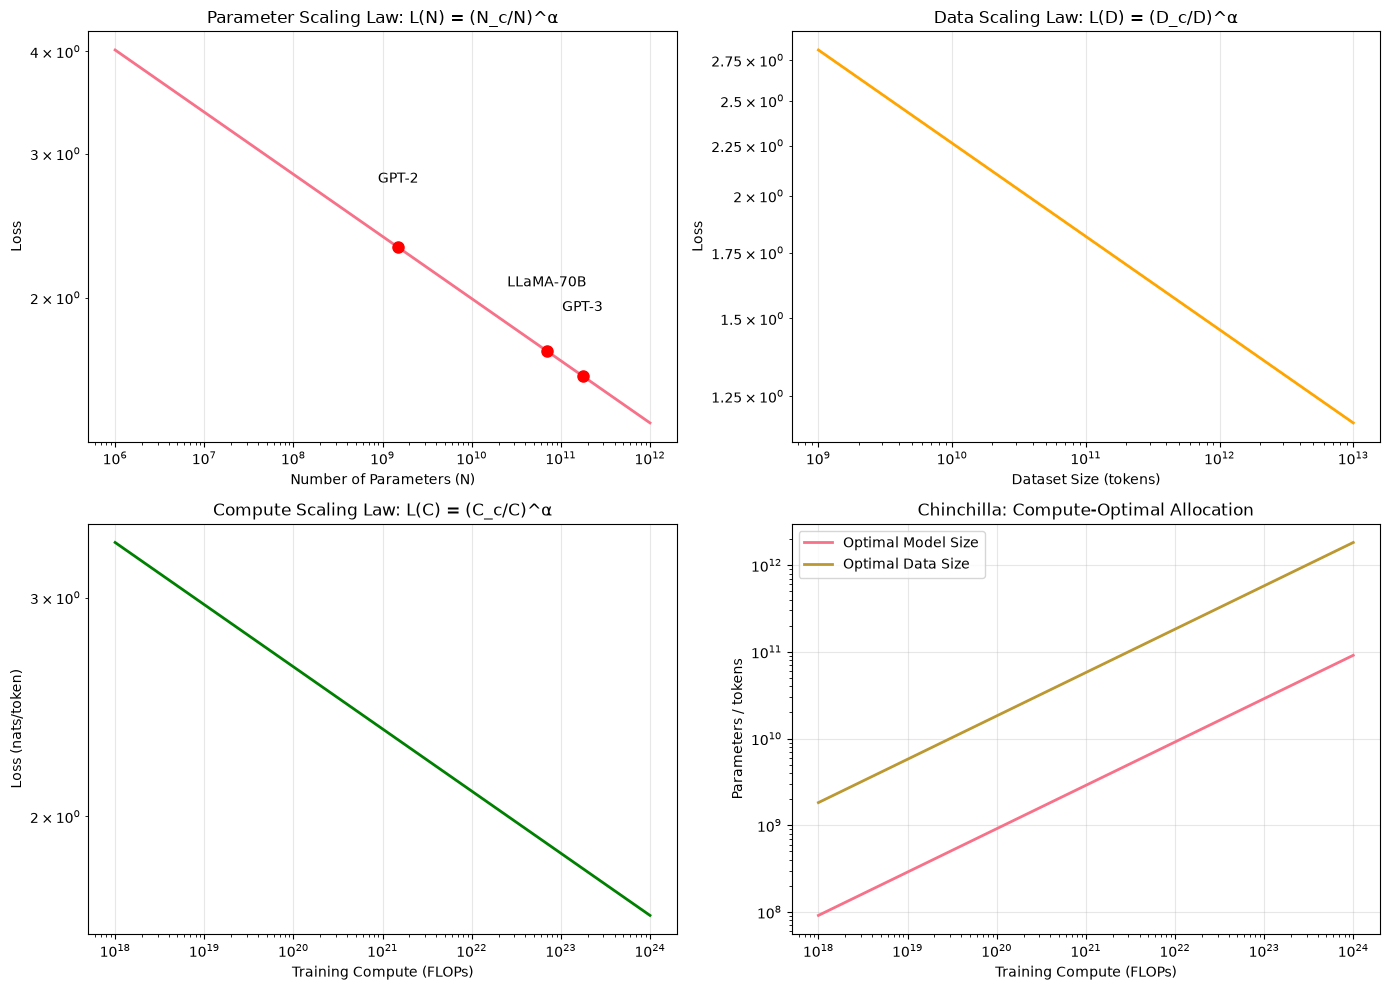

Scaling Laws Summary
Parameter Scaling: L ∝ N^(-0.076)
Data Scaling: L ∝ D^(-0.095)
Compute Scaling: L ∝ C^(-0.05)  (C in PF-days, Kaplan eq. 1.3)

Chinchilla Result: For optimal performance, scale
model size and data size equally with compute (N* ∝ C^0.5, D* ∝ C^0.5),
about 20 tokens per parameter: at C=1e24 FLOPs, N*≈9.13e+10 params, D*≈1.83e+12 tokens


In [11]:
def kaplan_scaling_law(
    N: np.ndarray,
    N_c: float = 8.8e13,
    alpha_N: float = 0.076
) -> np.ndarray:
    """
    Kaplan et al. parameter scaling law.
    
    L(N) = (N_c / N)^α_N
    
    Args:
        N: Number of parameters
        N_c: Critical scale parameter
        alpha_N: Scaling exponent
    
    Returns:
        Loss values
    """
    return (N_c / N) ** alpha_N


def data_scaling_law(
    D: np.ndarray,
    D_c: float = 5.4e13,
    alpha_D: float = 0.095
) -> np.ndarray:
    """
    Data scaling law.
    
    L(D) = (D_c / D)^α_D
    
    Args:
        D: Dataset size (tokens)
        D_c: Critical scale parameter
        alpha_D: Scaling exponent
    
    Returns:
        Loss values
    """
    return (D_c / D) ** alpha_D


PF_DAY_FLOPS = 1e15 * 86400  # one petaflop/s-day = 8.64e19 FLOPs


def compute_scaling_law(
    C_flops: np.ndarray,
    C_c_pfdays: float = 3.1e8,
    alpha_C: float = 0.050
) -> np.ndarray:
    """
    Kaplan et al. compute scaling law (their eq. 1.3, compute-efficient frontier).
    
    L(C_min) = (C_c^min / C_min)^α_C^min, with C_c^min ≈ 3.1e8 PF-days and α ≈ 0.050.
    Kaplan measure compute in PF-days, so FLOPs are converted first.
    
    Args:
        C_flops: Training compute in FLOPs
        C_c_pfdays: Critical scale in PF-days
        alpha_C: Scaling exponent
    
    Returns:
        Loss values (nats per token)
    """
    return (C_c_pfdays / (C_flops / PF_DAY_FLOPS)) ** alpha_C


assert 2 < compute_scaling_law(np.array([1e18]))[0] < 4, "loss at 1e18 FLOPs should be a few nats"


def chinchilla_optimal_allocation(
    compute_budget: float,
    a: float = 0.5,
    b: float = 0.5
) -> Tuple[float, float]:
    """
    Compute optimal model size and data size for given compute budget.
    
    Based on Chinchilla scaling laws (Hoffmann et al., 2022).
    
    N* ∝ C^a
    D* ∝ C^b
    
    Args:
        compute_budget: Available compute (FLOPs)
        a: Model size scaling exponent
        b: Data size scaling exponent
    
    Returns:
        Optimal (model_size, data_size)
    """
    # Two facts fix the constants: training cost C ≈ 6·N·D FLOPs, and Hoffmann et al.
    # found the optimum at roughly D ≈ 20·N tokens per parameter. Together:
    #   N* = sqrt(C / 120),  D* = 20 · N*
    # (a = b = 0.5 is exactly this square-root scaling).
    tokens_per_param = 20.0
    model_size = (compute_budget / (6.0 * tokens_per_param)) ** a
    data_size = tokens_per_param * model_size ** (b / a)
    return model_size, data_size


_N, _D = chinchilla_optimal_allocation(1e24)
assert abs(6 * _N * _D / 1e24 - 1) < 0.01, "6ND must equal the compute budget"
assert abs(_D / _N - 20) < 0.5, "Chinchilla: ~20 tokens per parameter"


# Visualize scaling laws
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Parameter scaling
N_range = np.logspace(6, 12, 100)  # 1M to 1T parameters
losses_N = kaplan_scaling_law(N_range)

axes[0, 0].loglog(N_range, losses_N, linewidth=2)
axes[0, 0].set_xlabel('Number of Parameters (N)')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Parameter Scaling Law: L(N) = (N_c/N)^α')
axes[0, 0].grid(True, alpha=0.3)

# Mark notable model sizes
notable_sizes = {
    'GPT-2': 1.5e9,
    'GPT-3': 175e9,
    'LLaMA-70B': 70e9,
}
for model_name, size in notable_sizes.items():
    if N_range.min() <= size <= N_range.max():
        loss = kaplan_scaling_law(np.array([size]))[0]
        axes[0, 0].plot(size, loss, 'ro', markersize=8)
        axes[0, 0].text(size, loss * 1.2, model_name, ha='center')

# Data scaling
D_range = np.logspace(9, 13, 100)  # 1B to 10T tokens
losses_D = data_scaling_law(D_range)

axes[0, 1].loglog(D_range, losses_D, linewidth=2, color='orange')
axes[0, 1].set_xlabel('Dataset Size (tokens)')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].set_title('Data Scaling Law: L(D) = (D_c/D)^α')
axes[0, 1].grid(True, alpha=0.3)

# Compute scaling
C_range = np.logspace(18, 24, 100)  # 1e18 to 1e24 FLOPs
losses_C = compute_scaling_law(C_range)

axes[1, 0].loglog(C_range, losses_C, linewidth=2, color='green')
axes[1, 0].set_xlabel('Training Compute (FLOPs)')
axes[1, 0].set_ylabel('Loss (nats/token)')
axes[1, 0].set_title('Compute Scaling Law: L(C) = (C_c/C)^α')
axes[1, 0].grid(True, alpha=0.3)

# Chinchilla optimal allocation
compute_budgets = np.logspace(18, 24, 50)
optimal_N = []
optimal_D = []

for C in compute_budgets:
    N_opt, D_opt = chinchilla_optimal_allocation(C)
    optimal_N.append(N_opt)
    optimal_D.append(D_opt)

optimal_N = np.array(optimal_N)
optimal_D = np.array(optimal_D)

axes[1, 1].loglog(compute_budgets, optimal_N, label='Optimal Model Size', linewidth=2)
axes[1, 1].loglog(compute_budgets, optimal_D, label='Optimal Data Size', linewidth=2)
axes[1, 1].set_xlabel('Training Compute (FLOPs)')
axes[1, 1].set_ylabel('Parameters / tokens')
axes[1, 1].set_title('Chinchilla: Compute-Optimal Allocation')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Scaling Laws Summary")
print("=" * 60)
print("Parameter Scaling: L ∝ N^(-0.076)")
print("Data Scaling: L ∝ D^(-0.095)")
print("Compute Scaling: L ∝ C^(-0.05)  (C in PF-days, Kaplan eq. 1.3)")
print("\nChinchilla Result: For optimal performance, scale")
print("model size and data size equally with compute (N* ∝ C^0.5, D* ∝ C^0.5),")
print(f"about 20 tokens per parameter: at C=1e24 FLOPs, N*≈{_N:.2e} params, D*≈{_D:.2e} tokens")
print("=" * 60)

(nb-math-memory)=
### Memory and Compute Requirements

$$N \approx 12\,L\,d^2 + V d, \qquad \text{bytes} \approx 16N + L\,s\,b\,h\left(34 + \frac{5as}{h}\right), \qquad \text{FLOPs/step} \approx 6N \cdot \text{tokens}$$


Memory and Compute Requirements (batch 8, mixed precision, Adam, no activation recomputation)
Model                      Params   Param+opt (GB)   Activations (GB)   PFLOP/step
GPT-2 Small (124M)          0.12B              2.0                5.6         0.01
GPT-2 Large (774M)          0.77B             12.4               27.9         0.04
GPT-3 Small (125M)          0.12B              2.0               17.2         0.01
GPT-3 Medium (350M)         0.35B              5.7               45.9         0.03
GPT-3 Large (760M)          0.76B             12.1               68.9         0.07
GPT-3 XL (1.3B)             1.31B             21.0               91.8         0.13
GPT-3 175B                174.56B           2793.0             2203.3        17.16
GPT-3 175B check: 174.6B parameters, 2793 GB of weights+optimizer state alone


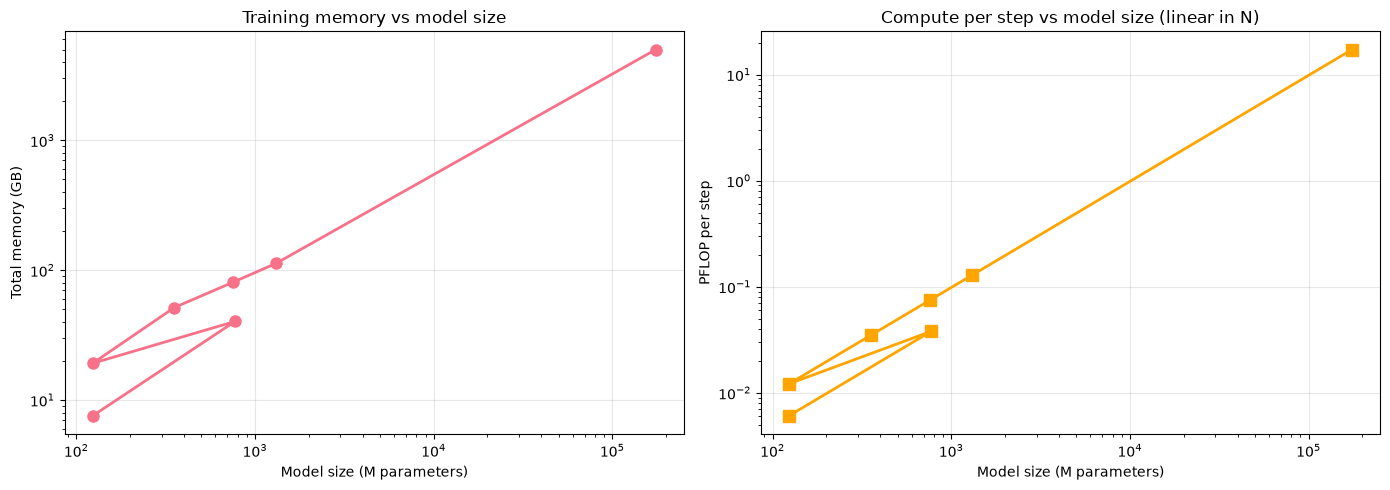

In [12]:
def estimate_training_requirements(
    num_layers: int,
    d_model: int,
    vocab_size: int,
    seq_length: int = 2048,
    batch_size: int = 1,
    num_heads: int | None = None,
) -> dict:
    """
    Estimate memory and compute for mixed-precision (fp16/bf16 + fp32 master) Adam training.

    Parameters are computed from the architecture, not taken as an input:
        per layer ≈ 12·d² (4·d² attention projections + 8·d² for the 4d-wide FFN),
        plus V·d embeddings (output projection assumed tied).
    Memory per parameter is 16 bytes: 2 (fp16 weight) + 2 (fp16 grad)
        + 4 (fp32 master weight) + 8 (fp32 Adam m and v).
    Activations per layer without recomputation follow Korthikanti et al. (2022):
        s·b·h·(34 + 5·a·s/h) bytes, for sequence s, batch b, hidden h and a heads.
    Compute: ≈ 6 · N · tokens FLOPs per step (forward 2N, backward 4N).
    """
    num_heads = num_heads or max(1, d_model // 128)
    num_params = 12 * num_layers * d_model**2 + vocab_size * d_model
    bytes_per_param = 2 + 2 + 4 + 8
    param_state_GB = num_params * bytes_per_param / 1e9
    s, b, h, a, L = seq_length, batch_size, d_model, num_heads, num_layers
    activation_GB = L * s * b * h * (34 + 5 * a * s / h) / 1e9
    flops_per_step = 6 * num_params * batch_size * seq_length
    return {
        "num_params": num_params,
        "param_state_GB": param_state_GB,      # weights + grads + master + Adam moments
        "activation_GB": activation_GB,
        "total_memory_GB": param_state_GB + activation_GB,
        "flops_per_step": flops_per_step,
    }


# (name, layers, d_model, context) — GPT-2 from Radford et al. 2019, GPT-3 from Brown et al. 2020, Table 2.1
model_configs = [
    ("GPT-2 Small (124M)",  12,  768,  1024),
    ("GPT-2 Large (774M)",  36, 1280,  1024),
    ("GPT-3 Small (125M)",  12,  768,  2048),
    ("GPT-3 Medium (350M)", 24, 1024,  2048),
    ("GPT-3 Large (760M)",  24, 1536,  2048),
    ("GPT-3 XL (1.3B)",     24, 2048,  2048),
    ("GPT-3 175B",          96, 12288, 2048),
]
VOCAB = 50257

print("Memory and Compute Requirements (batch 8, mixed precision, Adam, no activation recomputation)")
print("=" * 100)
print(f"{'Model':<22} {'Params':>10} {'Param+opt (GB)':>16} {'Activations (GB)':>18} {'PFLOP/step':>12}")
print("=" * 100)

rows = []
for name, layers, d_model, seq_len in model_configs:
    r = estimate_training_requirements(layers, d_model, VOCAB, seq_length=seq_len, batch_size=8)
    rows.append((name, r))
    print(f"{name:<22} {r['num_params']/1e9:>9.2f}B {r['param_state_GB']:>16.1f} {r['activation_GB']:>18.1f} {r['flops_per_step']/1e15:>12.2f}")
print("=" * 100)

gpt3 = dict(rows)["GPT-3 175B"]
assert abs(gpt3["num_params"] / 175e9 - 1) < 0.02, "GPT-3 config must give ~175B parameters"
assert gpt3["param_state_GB"] * 1e9 / gpt3["num_params"] == 16, "16 bytes per parameter"
print(f"GPT-3 175B check: {gpt3['num_params']/1e9:.1f}B parameters, {gpt3['param_state_GB']:.0f} GB of weights+optimizer state alone")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
params = [r["num_params"] / 1e6 for _, r in rows]
ax1.loglog(params, [r["total_memory_GB"] for _, r in rows], 'o-', linewidth=2, markersize=8)
ax1.set_xlabel('Model size (M parameters)')
ax1.set_ylabel('Total memory (GB)')
ax1.set_title('Training memory vs model size')
ax1.grid(True, alpha=0.3)
ax2.loglog(params, [r["flops_per_step"] / 1e15 for _, r in rows], 's-', linewidth=2, markersize=8, color='orange')
ax2.set_xlabel('Model size (M parameters)')
ax2.set_ylabel('PFLOP per step')
ax2.set_title('Compute per step vs model size (linear in N)')
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


(nb-math-numerics)=
## 7. Numerical Stability

$$W \sim \mathcal{N}\!\left(0, \tfrac{2}{n_{\text{in}}+n_{\text{out}}}\right) \text{ (Xavier)}, \qquad W \sim \mathcal{N}\!\left(0, \tfrac{2}{n_{\text{in}}}\right) \text{ (He)}, \qquad g \leftarrow \min\!\left(1, \tfrac{\tau}{\|g\|}\right) g$$

Numerical precision and stability are critical for training large models. This section explores floating-point precision, initialization strategies, and gradient clipping.

**Theory Reference**: See Chapter 2, Section 5 for complete treatment of numerical stability considerations.

Numerical Precision Demonstration: FP16 vs FP32
Original value (FP32): 1.00e-08
Converted to FP16: 0.00e+00
Relative error after conversion: 100.00% (100% = underflow to zero)
bf16 keeps fp32's 8 exponent bits, so the same value survives: 1.0011717677116394e-08

FP16 representable range:
  Maximum: 6.55e+04
  Smallest normal (positive): 6.10e-05
  Smallest subnormal: 5.96e-08  (1e-8 is below this, hence underflow to 0)
  Epsilon: 9.77e-04

FP32 representable range:
  Maximum: 3.40e+38
  Smallest normal (positive): 1.18e-38
  Epsilon: 1.19e-07

Gradient Clipping Demonstration
Gradient norm before clipping: 17258.97
Gradient norm after clipping: 1.00
Max norm threshold: 1.0
Clipping factor: 0.0001


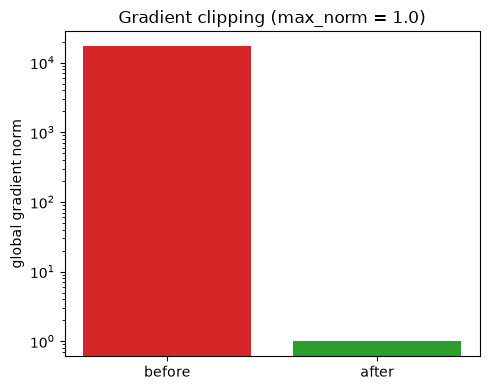


Initialization Strategies Comparison
Weight Distribution Statistics:

Xavier Initialization:
  Mean: -0.000058
  Std:  0.044246
  Theoretical std: 0.044194

He Initialization:
  Mean: 0.000031
  Std:  0.062392
  Theoretical std: 0.062500

Standard Initialization (0.01):
  Mean: -0.000005
  Std:  0.009996


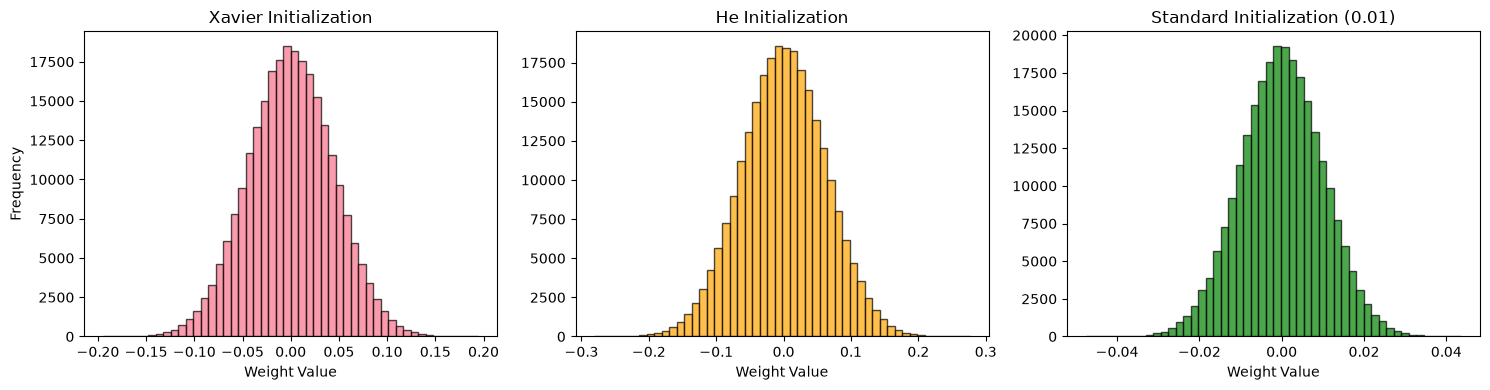

In [13]:
def demonstrate_fp16_underflow():
    """
    Demonstrate gradient underflow in FP16 precision.
    """
    print("Numerical Precision Demonstration: FP16 vs FP32")
    print("=" * 60)
    
    # Small gradient that might underflow in FP16
    grad_fp32 = torch.tensor([1e-8], dtype=torch.float32)
    grad_fp16 = torch.tensor([1e-8], dtype=torch.float16)
    
    print(f"Original value (FP32): {grad_fp32.item():.2e}")
    print(f"Converted to FP16: {grad_fp16.item():.2e}")
    print(f"Relative error after conversion: {abs(grad_fp32.item() - grad_fp16.item()) / grad_fp32.item() * 100:.2f}% (100% = underflow to zero)")
    print("bf16 keeps fp32's 8 exponent bits, so the same value survives:", torch.tensor([1e-8]).to(torch.bfloat16).item())
    
    # Show FP16 range limits
    print(f"\nFP16 representable range:")
    print(f"  Maximum: {torch.finfo(torch.float16).max:.2e}")
    print(f"  Smallest normal (positive): {torch.finfo(torch.float16).tiny:.2e}")
    print(f"  Smallest subnormal: {2.0**-24:.2e}  (1e-8 is below this, hence underflow to 0)")
    print(f"  Epsilon: {torch.finfo(torch.float16).eps:.2e}")
    
    print(f"\nFP32 representable range:")
    print(f"  Maximum: {torch.finfo(torch.float32).max:.2e}")
    print(f"  Smallest normal (positive): {torch.finfo(torch.float32).tiny:.2e}")
    print(f"  Epsilon: {torch.finfo(torch.float32).eps:.2e}")
    print("=" * 60)


def gradient_clipping_demo():
    """
    Demonstrate gradient clipping for stability.
    """
    print("\nGradient Clipping Demonstration")
    print("=" * 60)
    
    # Create parameters with large gradients
    params = [torch.randn(100, 100, requires_grad=True) for _ in range(3)]
    
    # Simulate large gradients (exploding gradient scenario)
    for p in params:
        p.grad = torch.randn_like(p) * 100  # Very large gradients
    
    # Compute gradient norm before clipping
    total_norm_before = torch.sqrt(sum(p.grad.norm()**2 for p in params))
    
    # Apply gradient clipping
    max_norm = 1.0
    torch.nn.utils.clip_grad_norm_(params, max_norm)
    
    # Compute gradient norm after clipping
    total_norm_after = torch.sqrt(sum(p.grad.norm()**2 for p in params))
    
    print(f"Gradient norm before clipping: {total_norm_before.item():.2f}")
    print(f"Gradient norm after clipping: {total_norm_after.item():.2f}")
    print(f"Max norm threshold: {max_norm}")
    print(f"Clipping factor: {max_norm / total_norm_before.item():.4f}")
    assert abs(total_norm_after.item() - max_norm) < 1e-3, "global norm must equal max_norm after clipping"
    plt.figure(figsize=(5, 4))
    plt.bar(["before", "after"], [total_norm_before.item(), total_norm_after.item()], color=["tab:red", "tab:green"])
    plt.yscale("log")
    plt.ylabel("global gradient norm")
    plt.title("Gradient clipping (max_norm = 1.0)")
    plt.tight_layout()
    plt.show()
    print("=" * 60)


def initialization_comparison():
    """
    Compare different initialization strategies.
    """
    print("\nInitialization Strategies Comparison")
    print("=" * 60)
    
    n_in = 512
    n_out = 512
    # Xavier/Glorot initialization
    xavier_weight = torch.randn(n_in, n_out) * math.sqrt(2.0 / (n_in + n_out))
    
    # He initialization
    he_weight = torch.randn(n_in, n_out) * math.sqrt(2.0 / n_in)
    
    # Standard initialization
    std_weight = torch.randn(n_in, n_out) * 0.01
    
    # Analyze distributions
    print("Weight Distribution Statistics:")
    print(f"\nXavier Initialization:")
    print(f"  Mean: {xavier_weight.mean():.6f}")
    print(f"  Std:  {xavier_weight.std():.6f}")
    print(f"  Theoretical std: {math.sqrt(2.0 / (n_in + n_out)):.6f}")
    
    print(f"\nHe Initialization:")
    print(f"  Mean: {he_weight.mean():.6f}")
    print(f"  Std:  {he_weight.std():.6f}")
    print(f"  Theoretical std: {math.sqrt(2.0 / n_in):.6f}")
    
    print(f"\nStandard Initialization (0.01):")
    print(f"  Mean: {std_weight.mean():.6f}")
    print(f"  Std:  {std_weight.std():.6f}")
    
    # Visualize distributions
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    axes[0].hist(xavier_weight.flatten().numpy(), bins=50, alpha=0.7, edgecolor='black')
    axes[0].set_title('Xavier Initialization')
    axes[0].set_xlabel('Weight Value')
    axes[0].set_ylabel('Frequency')
    
    axes[1].hist(he_weight.flatten().numpy(), bins=50, alpha=0.7, edgecolor='black', color='orange')
    axes[1].set_title('He Initialization')
    axes[1].set_xlabel('Weight Value')
    
    axes[2].hist(std_weight.flatten().numpy(), bins=50, alpha=0.7, edgecolor='black', color='green')
    axes[2].set_title('Standard Initialization (0.01)')
    axes[2].set_xlabel('Weight Value')
    
    plt.tight_layout()
    plt.show()
    print("=" * 60)


# Run demonstrations
demonstrate_fp16_underflow()
gradient_clipping_demo()
initialization_comparison()

(nb-math-loss-scaling)=
### Loss Scaling for Mixed Precision Training

$$\mathrm{loss}_{\text{scaled}} = s \cdot \mathrm{loss}, \qquad g = \frac{1}{s}\,\nabla \mathrm{loss}_{\text{scaled}}$$


Dynamic Loss Scaling Demonstration


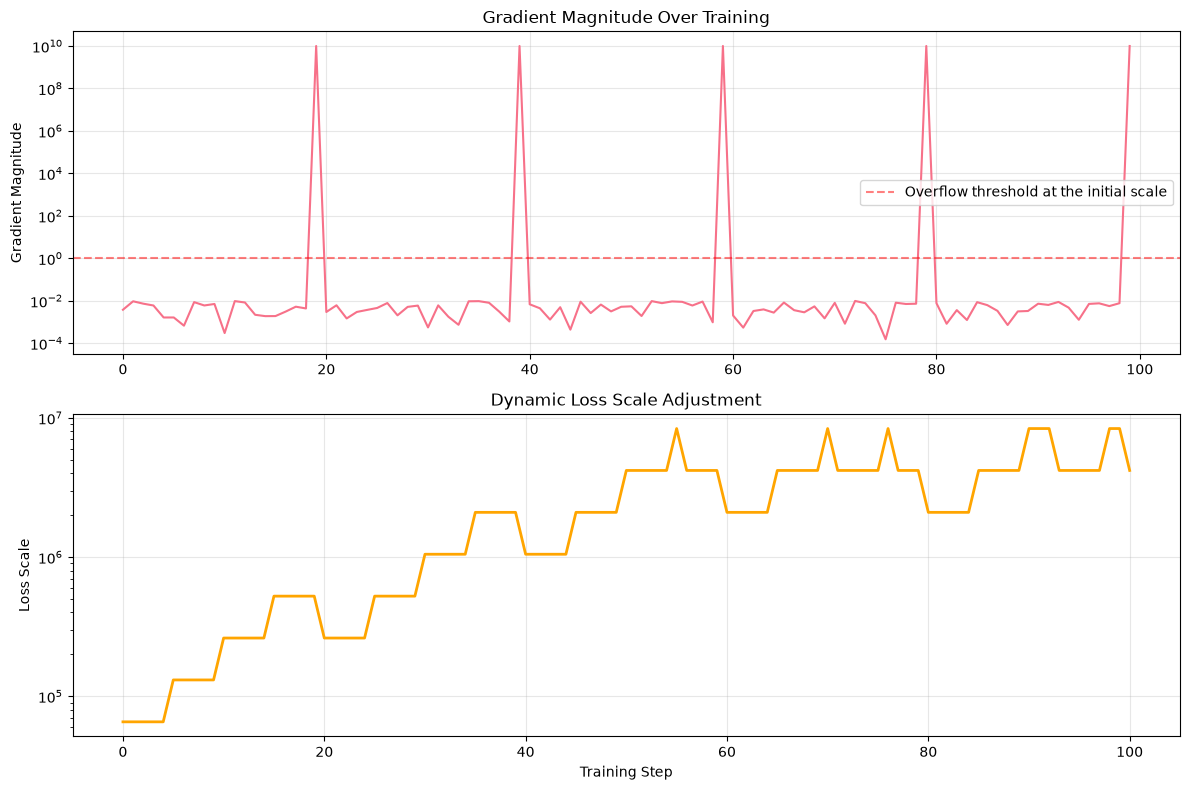

Initial loss scale: 65536
Final loss scale: 4194304
Number of scale adjustments: 24


In [14]:
# Demonstrate dynamic loss scaling
print("Dynamic Loss Scaling Demonstration")
print("=" * 60)

# Simulate training with varying gradient magnitudes
loss_scales = [2**16]  # Initial scale
steps_history = []
gradient_magnitudes = []

current_scale = 2**16
steps_since_growth = 0
growth_interval = 5  # PyTorch's GradScaler default is 2000; 5 keeps the 100-step demo readable

for step in range(100):
    # Simulate varying gradient magnitude
    # Occasionally create "overflow" scenario
    if step % 20 == 19:
        grad_magnitude = 1e10  # Overflow
    else:
        grad_magnitude = np.random.uniform(1e-4, 1e-2)
    
    gradient_magnitudes.append(grad_magnitude)
    steps_history.append(step)
    
    # Simulate overflow detection: the scaled gradient must fit in fp16
    scaled_grad = grad_magnitude * current_scale
    has_overflow = scaled_grad > torch.finfo(torch.float16).max
    
    if has_overflow:
        # Reduce scale
        current_scale *= 0.5
        steps_since_growth = 0
    else:
        # Successful step
        steps_since_growth += 1
        if steps_since_growth >= growth_interval:
            current_scale *= 2.0
            steps_since_growth = 0
    
    loss_scales.append(current_scale)

# Visualize dynamic scaling
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

ax1.plot(steps_history, gradient_magnitudes, linewidth=1.5)
ax1.set_ylabel('Gradient Magnitude')
ax1.set_title('Gradient Magnitude Over Training')
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)
ax1.axhline(y=torch.finfo(torch.float16).max / 2**16, color='r', linestyle='--', alpha=0.5, label='Overflow threshold at the initial scale')
ax1.legend()

ax2.plot(range(len(loss_scales)), loss_scales, linewidth=2, color='orange')
ax2.set_xlabel('Training Step')
ax2.set_ylabel('Loss Scale')
ax2.set_title('Dynamic Loss Scale Adjustment')
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Initial loss scale: {2**16}")
print(f"Final loss scale: {loss_scales[-1]:.0f}")
adjustments = sum(1 for a, b in zip(loss_scales, loss_scales[1:]) if a != b)
print(f"Number of scale adjustments: {adjustments}")
print("=" * 60)

## 8. Summary and Key Takeaways

Every bullet below is something a cell above computed and, where a number is involved, asserted.

### Probability and Information Theory
- **Entropy** (in bits) is maximal, log₂V, for the uniform distribution and falls as a distribution sharpens.
- **Cross-entropy** is the training loss; an untrained (random-logit) model has perplexity close to the vocabulary size.
- **KL divergence** is asymmetric, and is infinite where the approximating distribution puts zero mass on a possible outcome.

### Optimization
- Hand-written **Adam** (with bias correction) matches `torch.optim.Adam` step for step.
- On Rosenbrock, Adam reaches the optimum within 0.05 in 1000 steps; see the printed final values for the two SGD variants at this learning rate.
- **Warm-up plus cosine decay** holds at `min_lr` after `max_steps` and is never zero at step 0.

### Backpropagation and Architecture
- **Attention** rows sum to 1 in eval mode (dropout would rescale them in train mode).
- The gradient-flow experiment shows **LayerNorm rescuing a stack initialised with std 0.02**, but also that a Xavier-initialised stack does not vanish in the first place, and that **residual connections** keep layer-0 and last-layer gradient norms within 10× of each other.

### Scaling Laws
- Kaplan et al.: L ∝ N^-0.076, L ∝ D^-0.095, and L ∝ C^-0.050 with C in PF-days.
- **Chinchilla**: for a compute budget C ≈ 6·N·D, the optimum is about 20 tokens per parameter, so N* and D* both scale as √C.
- Parameter counts computed from (layers, width, vocabulary) reproduce GPT-3 175B within 2%; mixed-precision Adam needs 16 bytes per parameter before activations.
- Compute per step is linear in N and in tokens; only the attention-score term is quadratic in sequence length.

### Numerical Stability
- 1e-8 underflows to 0 in fp16 (below its smallest subnormal) but survives in bf16, which shares fp32's exponent range.
- **Dynamic loss scaling** halves the scale on overflow and grows it after a run of clean steps.
- **Gradient clipping** rescales the global norm to exactly `max_norm`.
- Xavier and He initialisation produce the predicted weight standard deviations.

## References

- Kingma & Ba (2014). "Adam: A Method for Stochastic Optimization" - [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)
- Kaplan et al. (2020). "Scaling Laws for Neural Language Models" - [arXiv:2001.08361](https://arxiv.org/abs/2001.08361)
- Hoffmann et al. (2022). "Training Compute-Optimal Large Language Models" - [arXiv:2203.15556](https://arxiv.org/abs/2203.15556)
- Ba et al. (2016). "Layer Normalization" - [arXiv:1607.06450](https://arxiv.org/abs/1607.06450)
- Vaswani et al. (2017). "Attention Is All You Need" - [arXiv:1706.03762](https://arxiv.org/abs/1706.03762)
- Micikevicius et al. (2017). "Mixed Precision Training" - [arXiv:1710.03740](https://arxiv.org/abs/1710.03740)
- Korthikanti et al. (2022). "Reducing Activation Recomputation in Large Transformer Models" - [arXiv:2205.05198](https://arxiv.org/abs/2205.05198)
- Brown et al. (2020). "Language Models are Few-Shot Learners" - [arXiv:2005.14165](https://arxiv.org/abs/2005.14165)

For the full derivations, see the [Mathematical Foundations chapter](../index.md).
